# Assignment 2: Tomato Leaves Results (M2 Draft)

**This notebook**
- Reports the **preliminary metrics** of the M2 Draft: a small CNN baseline trained from scratch and an ImageNet-pretrained ResNet-18 with a frozen backbone and with full fine-tuning.
- All models use one seed (42) and the published train / validation / test split. Seed variability is not yet measured.

The ResNet-18 comparison is still in progress: the training budget is short, and more seeds and settings are planned for the final milestone.

## Model definitions

- **CNN**: four convolution blocks (16, 32, 64, 64 channels) with batch normalisation, global average pooling, dropout 0.3 and a linear layer. No pretrained weights.
- **ResNet18Frozen**: ImageNet-pretrained ResNet-18; only the new eight-class linear layer is trained, and the backbone stays in evaluation mode.
- **ResNet18FineTune**: the same network with all layers trained at a ten times lower learning rate.

## 0. Setup

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score
from PIL import Image

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'Assignment2' else ROOT
sys.path.insert(0, str(ROOT / 'Assignment2'))
from data_loader import NAMES, list_files, read_tomato
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
MODELS = ['CNN', 'ResNet18Frozen', 'ResNet18FineTune']
SHORT = [n.replace(' virus', '\nvirus').replace('Septoria ', 'Septoria\n').replace('yellow leaf curl', 'yellow\nleaf curl') for n in NAMES]

## 1. Saved runs

In [2]:
runs = {}
for folder in sorted((ROOT / 'Assignment2' / 'outputs').glob('*_seed*')):
    if (folder / 'metrics.json').exists():
        info = json.loads((folder / 'metrics.json').read_text())
        runs[info['model']] = (folder, info)
pd.DataFrame([{'Model': m, 'Seed': runs[m][1]['seed'], 'Parameters': runs[m][1]['parameters'],
               'Trainable': runs[m][1]['trainable_parameters'], 'Epochs run': runs[m][1]['epochs_run'],
               'Selected epoch': runs[m][1]['best_epoch'], 'Learning rate': runs[m][1]['learning_rate'],
               'Median epoch seconds': round(pd.read_csv(runs[m][0] / 'history.csv')['seconds'].median())} for m in MODELS if m in runs]).set_index('Model')

,Seed,Parameters,Trainable,Epochs run,Selected epoch,Learning rate,Median epoch seconds
Model,,,,,,,
CNN,42,61384,61384,12,12,0.0010,56
ResNet18Frozen,42,11180616,4104,6,5,0.0010,194
ResNet18FineTune,42,11180616,11180616,4,2,0.0001,526


**Observation and comment**

The small CNN has 61,384 parameters. ResNet-18 has 11.2 million, of which the frozen variant trains only the 4,104 parameters of the new head. The CNN selected its last epoch (12 of 12), so it had not stopped improving; the budget, not convergence, ended its training. Frozen ResNet-18 selected epoch 5 of 6, and the fine-tuned model selected epoch 2 of 4. One epoch costs about 56 s for the CNN, 194 s for the frozen model and 526 s for full fine-tuning on the 16-thread CPU. The total fit time stored for the fine-tuned run is not usable, because its fourth epoch includes a pause of the computer (7,888 s); the median epoch time is used instead.

## 2. Validation comparison

Validation macro-F1 selected the checkpoint of every run.

In [3]:
pd.DataFrame([{'Model': m, 'Loss': runs[m][1]['validation']['loss'], 'Accuracy': runs[m][1]['validation']['accuracy'],
               'Macro-F1': runs[m][1]['validation']['macro_f1']} for m in MODELS if m in runs]).set_index('Model').round(4)

,Loss,Accuracy,Macro-F1
Model,,,
CNN,0.2330,0.9265,0.8991
ResNet18Frozen,0.2911,0.9148,0.8806
ResNet18FineTune,0.0909,0.9733,0.9594


**Observation and comment**

Fine-tuned ResNet-18 leads on validation (accuracy 0.973, macro-F1 0.959). The CNN (0.927, 0.899) is ahead of the frozen backbone (0.915, 0.881).

## 3. Held-out test results

The test set was used once per model, after the checkpoint had been selected.

In [4]:
test = pd.DataFrame([{'Model': m, 'Loss': runs[m][1]['test']['loss'], 'Accuracy': runs[m][1]['test']['accuracy'],
                      'Macro-F1': runs[m][1]['test']['macro_f1'], 'Inference ms/image': runs[m][1]['test']['inference_ms']}
                     for m in MODELS if m in runs]).set_index('Model')
test.round(4)

,Loss,Accuracy,Macro-F1,Inference ms/image
Model,,,,
CNN,0.2383,0.9220,0.8955,6.3545
ResNet18Frozen,0.2938,0.9120,0.8754,11.4733
ResNet18FineTune,0.0876,0.9705,0.9547,10.8878


**Observation and comment**

The test ranking matches validation. Fine-tuned ResNet-18 reaches 0.971 accuracy and 0.955 macro-F1, against 0.922 and 0.896 for the CNN and 0.912 and 0.875 for the frozen model. The gap between the fine-tuned model and the other two (about 5 points of accuracy) is large for one seed, but the gap between the CNN and the frozen model is about 1 point (roughly 18 images), which one seed cannot separate. The inference times are single measurements on a busy CPU and include data loading and normalisation, so they are only indicative; the frozen model, for instance, was timed at 17.0 ms per image on validation and 11.5 ms on test.

## 4. Learning curves

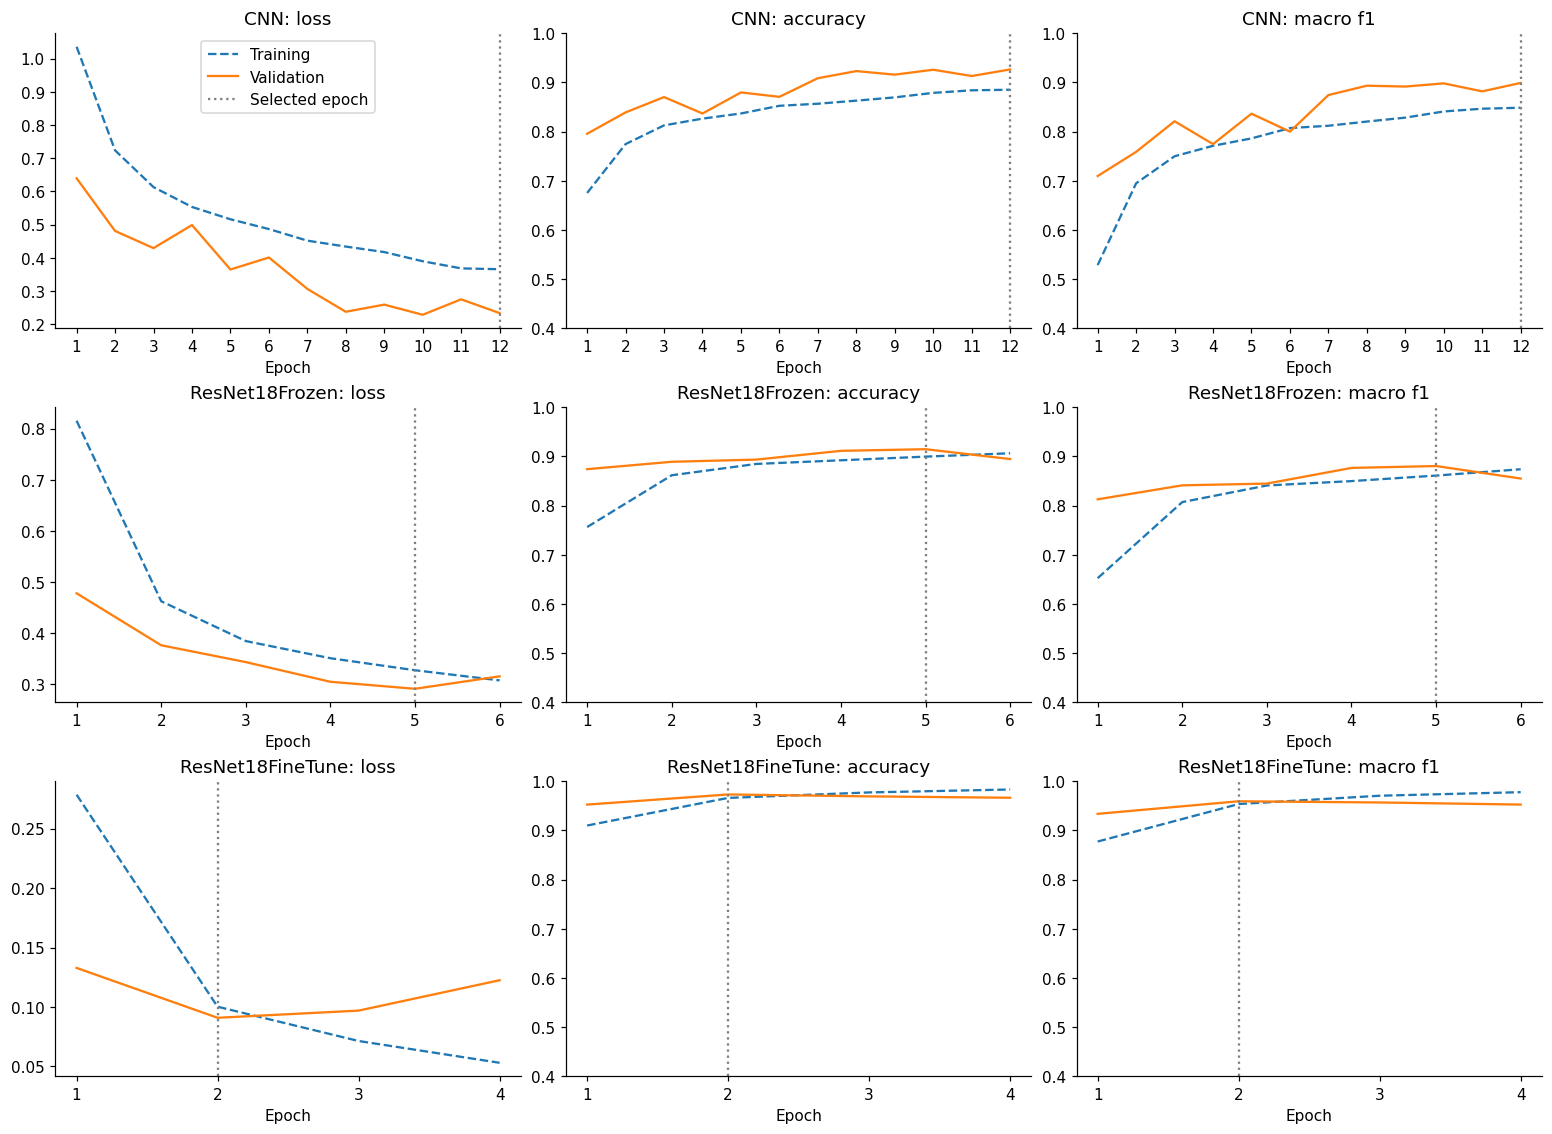

In [5]:
fig, axes = plt.subplots(len(MODELS), 3, figsize=(14, 3.4 * len(MODELS)), layout='constrained', squeeze=False)
for row, m in enumerate(MODELS):
    if m not in runs:
        continue
    history = pd.read_csv(runs[m][0] / 'history.csv')
    for ax, metric in zip(axes[row], ['loss', 'accuracy', 'macro_f1']):
        ax.plot(history['epoch'], history['train_' + metric], '--', label='Training')
        ax.plot(history['epoch'], history['val_' + metric], label='Validation')
        ax.axvline(runs[m][1]['best_epoch'], color='gray', linestyle=':', label='Selected epoch')
        ax.set(title=f'{m}: ' + metric.replace('_', ' '), xlabel='Epoch')
        ax.set_xticks(history['epoch'])
        if metric != 'loss':
            ax.set_ylim(0.4, 1)
axes[0, 0].legend()
plt.show()

**Observation and comment**

Validation scores sit above training scores for the CNN because training metrics are measured during the epoch with random flips and dropout. The CNN curves are still rising at epoch 12. For the frozen model, validation macro-F1 peaks at epoch 5 and drops at epoch 6, which shows how noisy this metric is when some classes have few validation images. The fine-tuned model reaches its best validation loss at epoch 2; after that the training loss keeps falling and the validation loss rises, so it starts to overfit within a few epochs at this learning rate.

## 5. Per-class results

Test F1 of each class. Classes are sorted in the dataset order.

In [6]:
predictions = {m: np.load(runs[m][0] / 'test_predictions.npz') for m in MODELS if m in runs}
labels = next(iter(predictions.values()))['labels']
per_class = pd.DataFrame({m: f1_score(labels, p['predictions'], labels=range(8), average=None) for m, p in predictions.items()},
                         index=pd.Index(NAMES, name='Class'))
per_class['Test images'] = np.bincount(labels, minlength=8)
per_class.round(3)

,CNN,ResNet18Frozen,ResNet18FineTune,Test images
Class,,,,
Bacterial spot,0.921,0.902,0.974,241
Early blight,0.775,0.765,0.938,117
Late blight,0.870,0.868,0.954,209
Leaf mold,0.895,0.825,0.921,125
Septoria leaf spot,0.910,0.881,0.963,223
Tomato yellow leaf curl virus,0.967,0.978,0.994,625
Tomato mosaic virus,0.857,0.821,0.909,59
Healthy,0.970,0.962,0.985,197


**Observation and comment**

Fine-tuned ResNet-18 has the highest F1 for every class. The hardest classes for the baseline models are Early blight (0.775 for the CNN, 0.765 frozen) and Tomato mosaic virus (0.857, 0.821, only 59 test images); fine-tuning raises Early blight to 0.938 but Tomato mosaic virus only to 0.909. Tomato yellow leaf curl virus, the largest class, is easiest for all models (0.967 to 0.994).

## 6. Test confusion matrices

Rows are true classes, normalised to 1; columns are predicted classes.

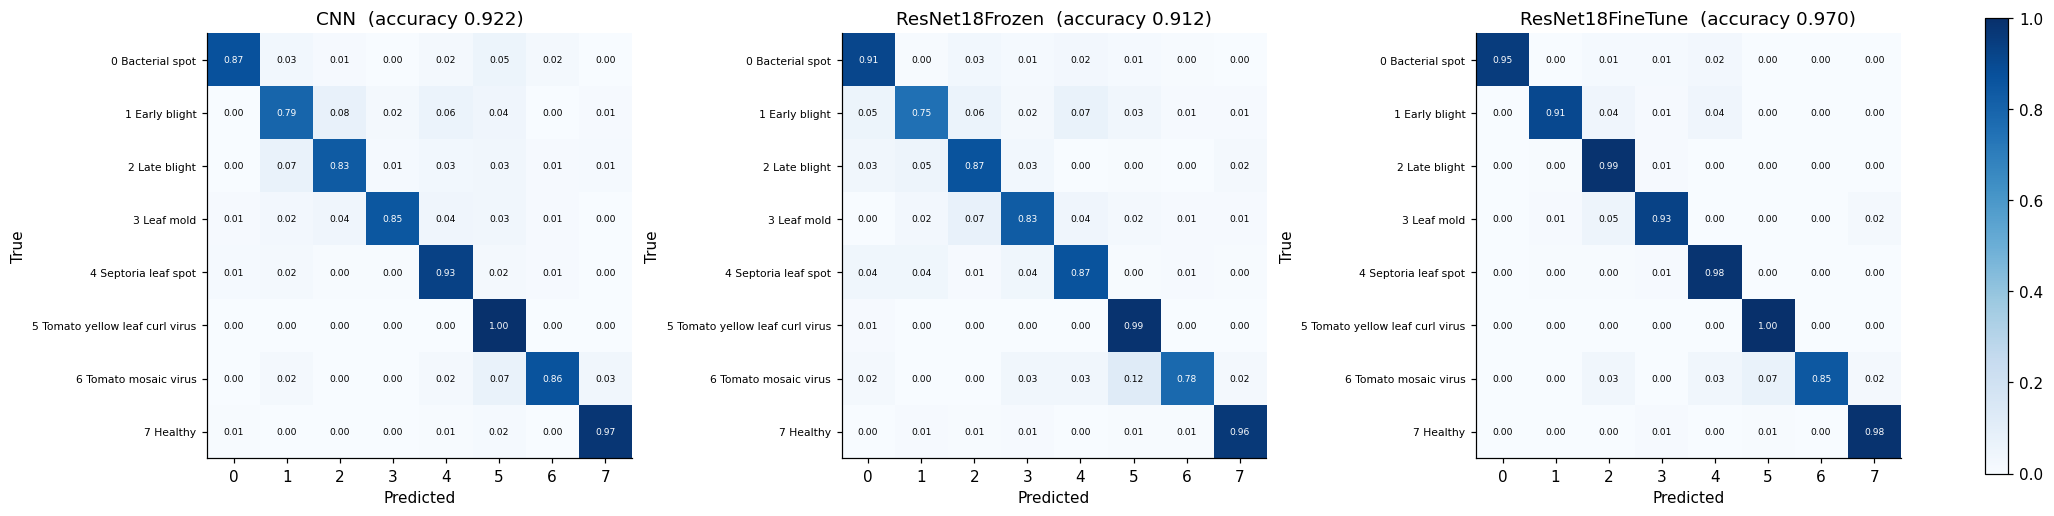

In [7]:
fig, axes = plt.subplots(1, len(predictions), figsize=(6.2 * len(predictions), 6), layout='constrained', squeeze=False)
for ax, (m, p) in zip(axes[0], predictions.items()):
    matrix = confusion_matrix(labels, p['predictions'], labels=range(8), normalize='true')
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
    ax.set(title=f'{m}  (accuracy {(labels == p["predictions"]).mean():.3f})', xlabel='Predicted', ylabel='True')
    ax.set_xticks(range(8), [str(i) for i in range(8)]); ax.set_yticks(range(8), [f'{i} {n}' for i, n in enumerate(NAMES)], fontsize=7)
    for i in range(8):
        for j in range(8):
            ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center', fontsize=6, color='white' if matrix[i, j] > 0.5 else 'black')
fig.colorbar(image, ax=axes, shrink=0.7)
plt.show()

**Observation and comment**

Most errors fall between visually similar diseases. Early blight is confused with Late blight and Septoria leaf spot by the CNN (8% and 6% of its images), and Tomato mosaic virus with Tomato yellow leaf curl virus by all three models (7% for the CNN and the fine-tuned model, 12% for the frozen model). Fine-tuning removes most of the Early blight and Late blight confusion but leaves the mosaic-versus-curl-virus confusion.

## 7. Effect of near-duplicate test images

The EDA found test images that have a near-identical image in the training set. Compare accuracy on those images with accuracy on the rest. The near-duplicate rule is the same as in the EDA: a 64-bit difference hash and a Hamming distance of at most 4 to any training image.

In [8]:
images, cached_labels, splits, _ = read_tomato()
def dhash(image):
    small = np.asarray(Image.fromarray(image).convert('L').resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return np.packbits((small[:, 1:] > small[:, :-1]).reshape(-1))
hashes = np.stack([dhash(image) for image in images])
popcount = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
train_hash, test_hash = hashes[splits == 0], hashes[splits == 2]
distance = np.concatenate([popcount[np.bitwise_xor(test_hash[s:s + 500, None, :], train_hash[None, :, :])].sum(axis=2).min(axis=1)
                           for s in range(0, len(test_hash), 500)])
near = distance <= 4
rows = []
for m, p in predictions.items():
    correct = p['predictions'] == labels
    rows.append({'Model': m, 'Near-duplicate test images': int(near.sum()), 'Accuracy on them': correct[near].mean(),
                 'Other test images': int((~near).sum()), 'Accuracy on the rest': correct[~near].mean(),
                 'Accuracy without them': correct[~near].mean(), 'Overall': correct.mean()})
pd.DataFrame(rows).set_index('Model').drop(columns='Accuracy without them').round(4)

,Near-duplicate test images,Accuracy on them,Other test images,Accuracy on the rest,Overall
Model,,,,,
CNN,88,0.9773,1708,0.9192,0.9220
ResNet18Frozen,88,0.9205,1708,0.9116,0.9120
ResNet18FineTune,88,0.9773,1708,0.9701,0.9705


**Observation and comment**

Near-duplicate images are easier than the rest for the CNN (0.977 on 88 images against 0.919 on the other 1,708), which is consistent with the model having seen a copy during training. For the two ResNet-18 models the difference is under 1 point. Removing the near-duplicates changes overall accuracy by less than 0.3 points for every model, so the leakage found in the EDA does not change the ranking of the models. With only 88 images, one image is worth 1.1 points, so these differences are indicative only.

## 8. Confident errors

For the model with the best validation macro-F1, show the test images it got wrong with the highest confidence.

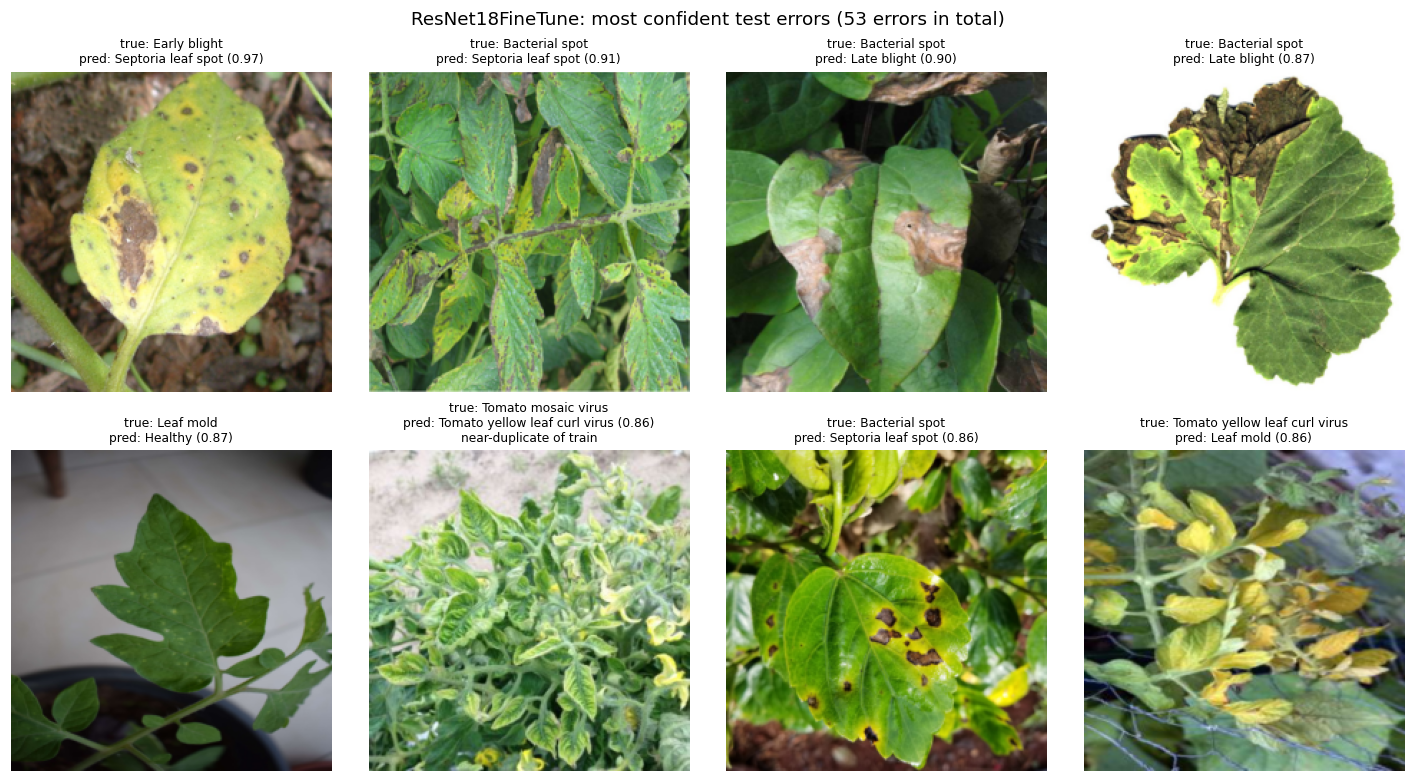

,Count
Errors,53
Errors that are near-duplicates of a training image,2
Confident errors (>= 0.9),2


In [9]:
best = max(predictions, key=lambda m: runs[m][1]['validation']['macro_f1'])
p = predictions[best]
wrong = np.flatnonzero(p['predictions'] != labels)
confidence = p['probabilities'].max(axis=1)
pick = wrong[np.argsort(-confidence[wrong])[:8]]
test_images = images[splits == 2]
fig, axes = plt.subplots(2, 4, figsize=(13, 7), layout='constrained')
for ax, index in zip(axes.ravel(), pick):
    ax.imshow(test_images[index]); ax.axis('off')
    ax.set_title(f'true: {NAMES[labels[index]]}\npred: {NAMES[p["predictions"][index]]} ({confidence[index]:.2f})' + ('\nnear-duplicate of train' if near[index] else ''), fontsize=8)
fig.suptitle(f'{best}: most confident test errors ({len(wrong)} errors in total)')
plt.show()
pd.Series({'Errors': len(wrong), 'Errors that are near-duplicates of a training image': int(near[wrong].sum()),
           'Confident errors (>= 0.9)': int((confidence[wrong] >= 0.9).sum())}, name='Count').to_frame()

**Observation and comment**

The fine-tuned model makes 53 errors on the test set; only 2 of them are near-duplicates of training images and only 2 have a confidence of 0.9 or higher. The most confident errors are field photographs with several leaves or a cluttered background. At least two of the eight images shown (the fourth and the seventh) do not look like tomato leaves, which suggests label noise in the web-sourced part of the data; this has not been checked against the source.

## 9. Errors by image source

The EDA used the original image size as a rough source label: 256 × 256 images look like PlantVillage crops, and other sizes look like web photographs. Compare error rates for the two groups on the test set.

In [10]:
from data_loader import RAW
paths, _, file_splits = list_files()
def size_of(path):
    with Image.open(RAW / path) as image:
        return image.size
test_sizes = [size_of(p) for p in paths[file_splits == 2]]
lab_style = np.array([size == (256, 256) for size in test_sizes])
rows = []
for m, p in predictions.items():
    correct = p['predictions'] == labels
    rows.append({'Model': m, '256 x 256 images': int(lab_style.sum()), 'Accuracy (256 x 256)': correct[lab_style].mean(),
                 'Other-size images': int((~lab_style).sum()), 'Accuracy (other sizes)': correct[~lab_style].mean()})
pd.DataFrame(rows).set_index('Model').round(4)

,256 x 256 images,Accuracy (256 x 256),Other-size images,Accuracy (other sizes)
Model,,,,
CNN,1714,0.9574,82,0.1829
ResNet18Frozen,1714,0.9411,82,0.3049
ResNet18FineTune,1714,0.9930,82,0.5000


**Observation and comment**

The size proxy separates the data sharply. On the 1,714 test images of 256 × 256, accuracy is 0.957 (CNN), 0.941 (frozen) and 0.993 (fine-tuned). On the 82 images of other sizes it is only 0.183, 0.305 and 0.500. For the fine-tuned model that means about 41 of its 53 errors (77%) come from the 4.6% of test images that are web-style. The size rule is a rough proxy, and the 82 images are too few for precise estimates, but the gap is far larger than any difference between models.

## 10. Discussion

- **Pretrained fine-tuning is clearly best in this draft.** Full fine-tuning of ResNet-18 gives 0.955 test macro-F1, against 0.896 for the CNN trained from scratch. It also reaches its best validation score after only two epochs.
- **A frozen ImageNet backbone did not beat the small CNN.** The frozen model scored 0.875 macro-F1 and the CNN 0.896. With one seed and a 1-point accuracy difference this is not a firm ranking. A likely reason is that ImageNet features are not tuned to fine leaf texture, but this has not been tested.
- **The comparison is not at equal compute.** The CNN ran 12 epochs and was still improving, the frozen model 6 and the fine-tuned model 4. The baseline is probably under-trained, so the gap to the fine-tuned model may shrink with a longer run.
- **The hard part is the domain, not the architecture.** All models are above 94% accuracy on 256 × 256 lab-style images and between 18% and 50% on the small set of web-style photographs. The final report should keep these two groups separate, and could add stronger augmentation or more web-style training data.
- **Leakage is present but does not change the ranking.** Near-duplicate test images are slightly easier for the CNN, but removing them moves overall accuracy by less than 0.3 points.
- **Limits of this draft.** One seed per model, short training budgets and no hyper-parameter search. These results are preliminary and are not yet suitable for claims about small differences between models.

## Status and next steps

- Pretrained model: frozen and fine-tuned ResNet-18 have each been trained once with a short budget. Longer fine-tuning and a learning-rate check are still to do.
- Repeat the three models with seeds 43-46 and report mean ± SD, as in Assignment 1.
- Decide whether to re-split the data so that near-duplicate photographs stay in one partition, and re-run all models on that split.
- Add the remaining analyses from the M1 plan: per-class error analysis by image source and a training-cost comparison.